## Libraries ##

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import networkx as nx
import matplotlib.pyplot as plt
import scipy.linalg as la
import tqdm as tqdm

## Data Loading ##

In [2]:
A_d = np.load("noisy.npy")

data = np.load("ER_CM_ensemble.npz")
seeds = data["seeds"]
A_er = data["A_er"]
A_cm = data["A_cm"]

N = A_d.shape[0]
print(N)

62


## Noisy voter dynamics ##

In [3]:
def noisy(t, x, A, F, B, R):
    Ax = A @ x
    k = A.sum(axis=1)

    k_safe = np.where(k > 0, k, 1.0)
    coupling = Ax / k_safe
    coupling[k == 0] = 0.0  

    return F - B * x + R * coupling


In [4]:
#Parameters and inital condition
F = 0.2
B = 2.0
R = 1.8

tf = 10.0
n_steps = 2000
dt = tf / n_steps
np.random.seed(1)  # Set the seed
taus = np.linspace(dt, tf, n_steps)
x0 = 0.1*np.random.rand(N)

DATA

In [5]:
sol_d = solve_ivp(noisy, (dt, tf), x0,t_eval=taus, args=(A_d, F, B, R))

#Saving
filename = f"dtraj_noisy_d.npz"
np.savez(filename, t=sol_d.t, x=sol_d.y, A=A_d, F=F, B=B, R=R)




In [6]:
import numpy as np
from tqdm import tqdm
from scipy.integrate import solve_ivp

# --------------------------
# Load ensemble networks
# --------------------------
data = np.load("ER_CM_ensemble.npz", allow_pickle=True)
seeds = data["seeds"]
A_er  = data["A_er"]   # (z, N, N)
A_cm  = data["A_cm"]   # (z, N, N)

z = len(seeds)
dim = x0.shape[0]
T = len(taus)

# ============================================================
# ER ensemble
# ============================================================
x_er = np.zeros((z, dim, T))
status_er = np.zeros(z, dtype=int)
message_er = np.empty(z, dtype=object)

for i, seed in tqdm(enumerate(seeds), total=z, desc="Noisy dynamics on ER ensemble"):
    sol = solve_ivp(
        noisy,
        (dt, tf),
        x0,
        t_eval=taus,
        args=(A_er[i], F, B, R)
    )
    x_er[i] = sol.y
    status_er[i] = sol.status
    message_er[i] = sol.message

np.savez_compressed(
    "dtraj_noisy_er_ensemble.npz",
    t=taus,
    x=x_er,          # (z, dim, T)
    seeds=seeds,
    F=F, B=B, R=R,
    status=status_er,
    message=message_er
)

# ============================================================
# CM ensemble
# ============================================================
x_cm = np.zeros((z, dim, T))
status_cm = np.zeros(z, dtype=int)
message_cm = np.empty(z, dtype=object)

for i, seed in tqdm(enumerate(seeds), total=z, desc="Noisy dynamics on CM ensemble"):
    sol = solve_ivp(
        noisy,
        (dt, tf),
        x0,
        t_eval=taus,
        args=(A_cm[i], F, B, R)
    )
    x_cm[i] = sol.y
    status_cm[i] = sol.status
    message_cm[i] = sol.message

np.savez_compressed(
    "dtraj_noisy_cm_ensemble.npz",
    t=taus,
    x=x_cm,          # (z, dim, T)
    seeds=seeds,
    F=F, B=B, R=R,
    status=status_cm,
    message=message_cm
)


Noisy dynamics on CM ensemble: 100%|██████████| 100/100 [00:00<00:00, 483.40it/s]


## Thermodynamics functions ##

In [7]:
def jac_noisy(t, x, A, B, R):
    N = len(x)
    k = A.sum(axis=1)

    k_safe = np.where(k > 0, k, 1.0)
    Dk_inv = np.diag(1.0 / k_safe)

    J = -B * np.eye(N) + R * (Dk_inv @ A)

    
    zero = (k == 0)
    if np.any(zero):
        J[zero, :] = 0.0
        J[zero, zero] = -B  

    return J



In [8]:
def thermo(t, U, J, dt, eps):

    # Liouville
    Udot = J @ U + U @ J.T
    U = U + dt * Udot

    # symmetry
    U = 0.5 * (U + U.T)
    U = U.real

    # spectral projection → density matrix
    w, V = la.eigh(U)
    w = np.maximum(w, eps)
    w = w / np.sum(w)
    rho = V @ np.diag(w) @ V.T

    log_rho = V @ np.diag(np.log(w)) @ V.T

    # entropy
    S = -np.sum(w * np.log(w))

    # symmetric generator
    D = 0.5 * (J + J.T)
    D = D.real

    D_r = V.T @ D @ V
    D_r = 0.5 * (D_r + D_r.T)

    Tr_rhoD = np.sum(w * np.diag(D_r))
    E = -2 * Tr_rhoD

    Tr_rhoD_logrho = np.sum(w * np.diag(D_r) * np.log(w))
    cov = Tr_rhoD_logrho + Tr_rhoD * S
    S_dot = -2 * cov

    # equilibrium reference
    d, _ = la.eigh(D)
    a = 2 * t * d
    a_max = np.max(a)
    log_Z = a_max + np.log(np.sum(np.exp(a - a_max)))

    div_kl = t * E - S + log_Z

    return rho, S, S_dot, E, div_kl

    

## Results ##

In [9]:
k0 = np.array([np.any(A_er[i].sum(axis=1) == 0) for i in range(A_er.shape[0])])
print("Fraction with k=0:", k0.mean())


Fraction with k=0: 0.27


### ER ###

In [10]:
import numpy as np
import scipy.linalg as la
from tqdm import tqdm





print(f"Δt = {dt}")
print(f"Number of steps: {len(taus)}")

eps = 1e-12
stride = 5

# --------------------------
# Load trajectories + ensemble (ER)
# --------------------------
data_trj_er = np.load("dtraj_noisy_er_ensemble.npz", allow_pickle=True)
x_er = data_trj_er["x"]  # (z, N, T)

data_nm = np.load("ER_CM_ensemble.npz", allow_pickle=True)
seeds = data_nm["seeds"]
A_er  = data_nm["A_er"]  # (z, N, N)

z, N, T = x_er.shape
taus_samp = taus[::stride]
n_samp = len(taus_samp)

# --------------------------
# Containers for ALL (NaN for failures)
# --------------------------
entropy       = np.full((z, n_samp), np.nan)
entropy_rate  = np.full((z, n_samp), np.nan)
energy        = np.full((z, n_samp), np.nan)
divergence    = np.full((z, n_samp), np.nan)

ok = np.zeros(z, dtype=bool)

# --------------------------
# Failure diagnostics (separate)
# --------------------------
fail_i      = []
fail_seed   = []
fail_step   = []
fail_time   = []
fail_reason = []

fail_file = "thermo_noisy_er_failures.npz"
good_partial_file = "thermo_noisy_er_good_partial.npz"
good_final_file   = "thermo_noisy_er_good_final.npz"

good_idx = []

# --------------------------
# Helper: save failures (separate file)
# --------------------------
def save_failures():
    np.savez_compressed(
        fail_file,
        i=np.array(fail_i, dtype=int),
        seed=np.array(fail_seed, dtype=int),
        step=np.array(fail_step, dtype=int),
        time=np.array(fail_time, dtype=float),
        reason=np.array(fail_reason, dtype=object)
    )

# --------------------------
# Helper: save good progress (ONLY good runs)
# --------------------------
def save_good_progress(path):
    gi = np.array(good_idx, dtype=int)
    np.savez_compressed(
        path,
        good_idx=gi,
        seeds=seeds[gi],
        taus=taus,
        stride=stride,
        taus_samp=taus_samp,
        entropy=entropy[gi],
        entropy_rate=entropy_rate[gi],
        energy=energy[gi],
        divergence=divergence[gi],
        dt=dt,
        eps=eps,
        B=B,
        R=R
    )

# --------------------------
# Main loop
# --------------------------
for i, seed in tqdm(
        enumerate(seeds),
        total=len(seeds),
        desc="ER ensemble thermo (Noisy, skip on error)"
    ):

    try:
        U = np.eye(N)
        U /= np.trace(U)

        A_i = A_er[i]
        x_i = x_er[i]

        # --- Build J once (time/state independent) ---
        # (need a vector x just for its length)
        x_dummy = x_i[:, 0]
        J = jac_noisy(taus[0], x_dummy, A_i, B, R)

        # Optional safety: avoid division-by-zero in Dk_inv if k has zeros
        # If you want to skip those networks instead of crashing, leave as-is and it will go to except.
        if not np.all(np.isfinite(J)):
            raise FloatingPointError("J contains NaN/Inf (likely zero out-degree -> 1/k)")

        idx = 0

        for k in range(len(taus)):

            t = taus[k]

            # Liouville update
            Udot = J @ U + U @ J.T
            U += dt * Udot
            U = 0.5 * (U + U.T)
            U = U.real

            trU = np.trace(U).real
            if abs(trU) < eps:
                trU = eps if trU >= 0 else -eps
            U /= trU

            if k % stride == 0:

                if not np.all(np.isfinite(U)):
                    raise FloatingPointError("U contains NaN/Inf")

                # eigendecomposition
                w, V = la.eigh(U, check_finite=False)
                w = np.maximum(w, eps)
                w /= np.sum(w)

                # entropy
                S = -np.sum(w * np.log(w))

                # symmetric generator (constant here)
                D = 0.5 * (J + J.T)
                D = D.real

                D_r = V.T @ D @ V
                D_r = 0.5 * (D_r + D_r.T)

                Tr_rhoD = np.sum(w * np.diag(D_r))
                E = -2 * Tr_rhoD

                Tr_rhoD_logrho = np.sum(w * np.diag(D_r) * np.log(w))
                cov = Tr_rhoD_logrho + Tr_rhoD * S
                Sdot = -2 * cov

                # equilibrium reference
                d, _ = la.eigh(D, check_finite=False)
                a = 2 * t * d
                a_max = np.max(a)
                log_Z = a_max + np.log(np.sum(np.exp(a - a_max)))

                div = t * E - S + log_Z

                entropy[i, idx]      = S
                entropy_rate[i, idx] = Sdot
                energy[i, idx]       = E
                divergence[i, idx]   = div

                idx += 1

        # --------------------------
        # SUCCESS: mark + checkpoint ONLY now
        # --------------------------
        ok[i] = True
        good_idx.append(i)
        save_good_progress(good_partial_file)

    except Exception as e:
        # --------------------------
        # FAILURE: log in separate file, skip
        # --------------------------
        ok[i] = False
        fail_i.append(int(i))
        fail_seed.append(int(seed))
        fail_step.append(int(k) if "k" in locals() else -1)
        fail_time.append(float(t) if "t" in locals() else np.nan)
        fail_reason.append(repr(e))

        if len(fail_reason) <= 3:
            print(f"[FAIL] i={i}, seed={seed}, k={fail_step[-1]}, t={fail_time[-1]}, err={fail_reason[-1]}")

        save_failures()

# --------------------------
# FINAL SAVE: only good realizations
# --------------------------
print(f"Good runs: {len(good_idx)} / {z}")
save_good_progress(good_final_file)


Δt = 0.005
Number of steps: 2000


ER ensemble thermo (Noisy, skip on error): 100%|██████████| 100/100 [00:35<00:00,  2.83it/s]

Good runs: 100 / 100


Loaded 100 valid runs.
taus_samp length: 400


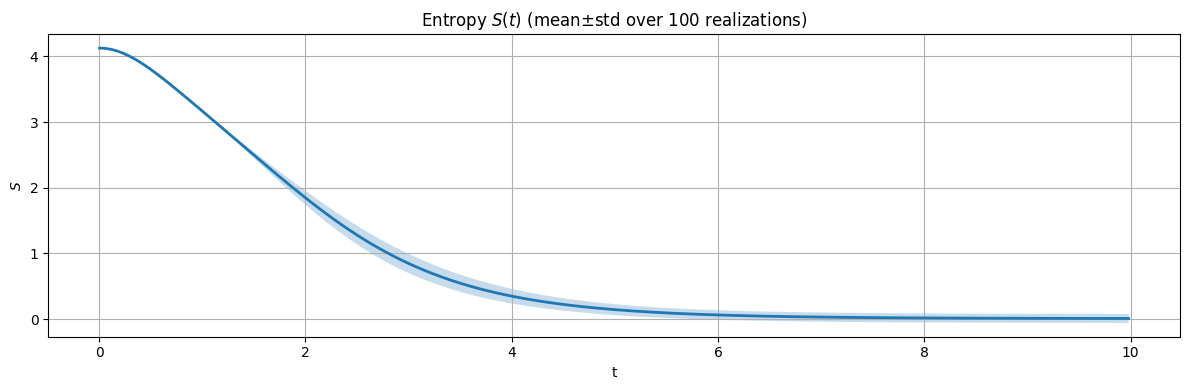

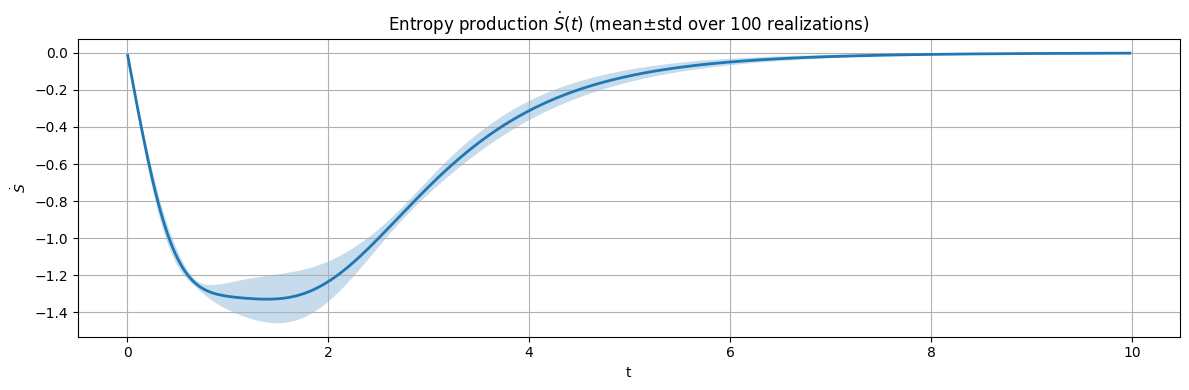

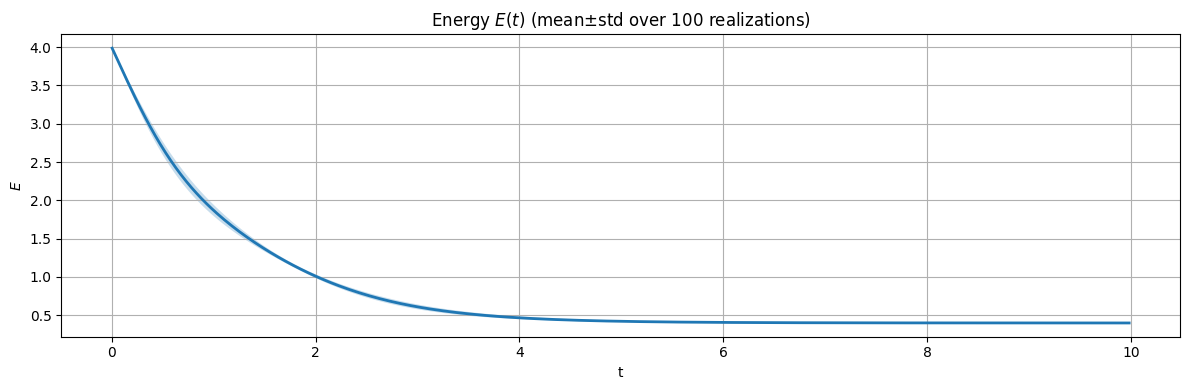

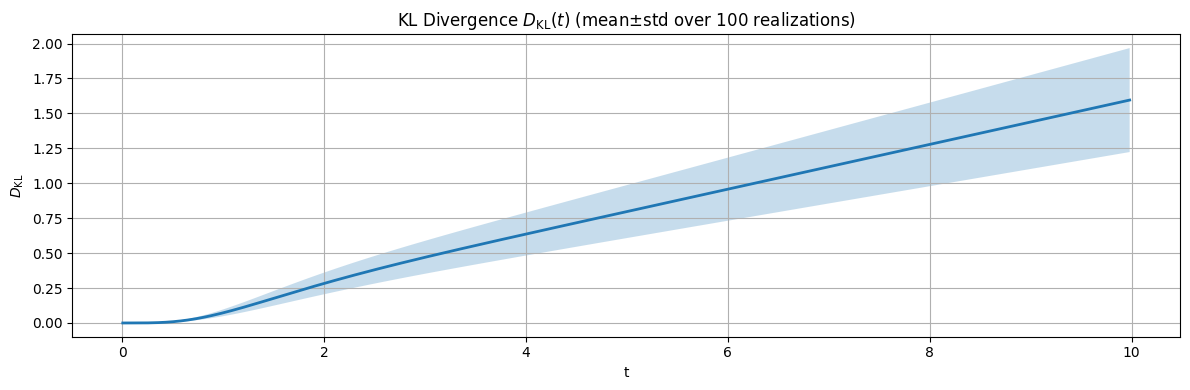

In [11]:
import numpy as np
import matplotlib.pyplot as plt

common_kwargs = dict(lw=2)
shade_alpha = 0.25   # trasparenza banda std

# ============================================================
# Load ONLY valid runs (good realizations)
# ============================================================
good_final_file = "thermo_noisy_er_good_final.npz"   # <- quello che hai salvato
data = np.load(good_final_file, allow_pickle=True)

taus_samp     = data["taus_samp"]
good_idx      = data["good_idx"]
seeds_good    = data["seeds"]

entropy       = data["entropy"]        # shape (z_good, n_samp)
entropy_rate  = data["entropy_rate"]   # shape (z_good, n_samp)
energy        = data["energy"]         # shape (z_good, n_samp)
divergence    = data["divergence"]     # shape (z_good, n_samp)

print(f"Loaded {len(good_idx)} valid runs.")
print(f"taus_samp length: {len(taus_samp)}")

# ============================================================
# Utility: plot mean ± std ACROSS REALIZATIONS (axis=0)
# ============================================================
def plot_mean_std(x, y, title, ylabel):
    """
    y shape: (n_realizations, len(x))
    mean/std computed across realizations, NOT across time.
    """
    # safety: ignore NaNs just in case
    y_mean = np.nanmean(y, axis=0)
    y_std  = np.nanstd(y, axis=0)

    plt.figure(figsize=(12, 4))
    plt.plot(x, y_mean, **common_kwargs)
    plt.fill_between(
        x,
        y_mean - y_std,
        y_mean + y_std,
        alpha=shade_alpha
    )
    plt.title(title)
    plt.xlabel("t")
    plt.ylabel(ylabel)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ============================================================
# Entropy
# ============================================================
plot_mean_std(
    taus_samp,
    entropy,
    title=f"Entropy $S(t)$ (mean±std over {len(good_idx)} realizations)",
    ylabel="$S$"
)

# ============================================================
# Entropy production
# ============================================================
plot_mean_std(
    taus_samp,
    entropy_rate,
    title=f"Entropy production $\\dot{{S}}(t)$ (mean±std over {len(good_idx)} realizations)",
    ylabel=r"$\dot S$"
)

# ============================================================
# Energy
# ============================================================
plot_mean_std(
    taus_samp,
    energy,
    title=f"Energy $E(t)$ (mean±std over {len(good_idx)} realizations)",
    ylabel="$E$"
)

# ============================================================
# KL Divergence
# ============================================================
plot_mean_std(
    taus_samp,
    divergence,
    title=f"KL Divergence $D_{{\\mathrm{{KL}}}}(t)$ (mean±std over {len(good_idx)} realizations)",
    ylabel=r"$D_{\mathrm{KL}}$"
)



### CM ###

In [12]:
import numpy as np
import scipy.linalg as la
from tqdm import tqdm




print(f"Δt = {dt}")
print(f"Number of steps: {len(taus)}")

eps = 1e-12
stride = 5

# --------------------------
# Load trajectories + ensemble (CM)
# --------------------------
data_trj_cm = np.load("dtraj_noisy_cm_ensemble.npz", allow_pickle=True)
x_cm = data_trj_cm["x"]  # (z, N, T)

data_nm = np.load("ER_CM_ensemble.npz", allow_pickle=True)
seeds = data_nm["seeds"]
A_cm  = data_nm["A_cm"]  # (z, N, N)

z, N, T = x_cm.shape
taus_samp = taus[::stride]
n_samp = len(taus_samp)

# --------------------------
# Containers for ALL (NaN for failures)
# --------------------------
entropy       = np.full((z, n_samp), np.nan)
entropy_rate  = np.full((z, n_samp), np.nan)
energy        = np.full((z, n_samp), np.nan)
divergence    = np.full((z, n_samp), np.nan)

ok = np.zeros(z, dtype=bool)

# --------------------------
# Failure diagnostics (separate)
# --------------------------
fail_i      = []
fail_seed   = []
fail_step   = []
fail_time   = []
fail_reason = []

fail_file = "thermo_noisy_cm_failures.npz"
good_partial_file = "thermo_noisy_cm_good_partial.npz"
good_final_file   = "thermo_noisy_cm_good_final.npz"

good_idx = []

# --------------------------
# Helper: save failures (separate file)
# --------------------------
def save_failures():
    np.savez_compressed(
        fail_file,
        i=np.array(fail_i, dtype=int),
        seed=np.array(fail_seed, dtype=int),
        step=np.array(fail_step, dtype=int),
        time=np.array(fail_time, dtype=float),
        reason=np.array(fail_reason, dtype=object)
    )

# --------------------------
# Helper: save good progress (ONLY good runs)
# --------------------------
def save_good_progress(path):
    gi = np.array(good_idx, dtype=int)
    np.savez_compressed(
        path,
        good_idx=gi,
        seeds=seeds[gi],
        taus=taus,
        stride=stride,
        taus_samp=taus_samp,
        entropy=entropy[gi],
        entropy_rate=entropy_rate[gi],
        energy=energy[gi],
        divergence=divergence[gi],
        dt=dt,
        eps=eps,
        B=B,
        R=R
    )

# --------------------------
# Main loop
# --------------------------
for i, seed in tqdm(
        enumerate(seeds),
        total=len(seeds),
        desc="CM ensemble thermo (Noisy, skip on error)"
    ):

    try:
        U = np.eye(N)
        U /= np.trace(U)

        A_i = A_cm[i]
        x_i = x_cm[i]

        # --- Build J once (time/state independent) ---
        x_dummy = x_i[:, 0]
        J = jac_noisy(taus[0], x_dummy, A_i, B, R)

        if not np.all(np.isfinite(J)):
            raise FloatingPointError("J contains NaN/Inf (likely zero out-degree -> 1/k)")

        idx = 0

        for k in range(len(taus)):

            t = taus[k]

            # Liouville update
            Udot = J @ U + U @ J.T
            U += dt * Udot
            U = 0.5 * (U + U.T)
            U = U.real

            trU = np.trace(U).real
            if abs(trU) < eps:
                trU = eps if trU >= 0 else -eps
            U /= trU

            if k % stride == 0:

                if not np.all(np.isfinite(U)):
                    raise FloatingPointError("U contains NaN/Inf")

                # eigendecomposition
                w, V = la.eigh(U, check_finite=False)
                w = np.maximum(w, eps)
                w /= np.sum(w)

                # entropy
                S = -np.sum(w * np.log(w))

                # symmetric generator
                D = 0.5 * (J + J.T)
                D = D.real

                D_r = V.T @ D @ V
                D_r = 0.5 * (D_r + D_r.T)

                Tr_rhoD = np.sum(w * np.diag(D_r))
                E = -2 * Tr_rhoD

                Tr_rhoD_logrho = np.sum(w * np.diag(D_r) * np.log(w))
                cov = Tr_rhoD_logrho + Tr_rhoD * S
                Sdot = -2 * cov

                # equilibrium reference
                d, _ = la.eigh(D, check_finite=False)
                a = 2 * t * d
                a_max = np.max(a)
                log_Z = a_max + np.log(np.sum(np.exp(a - a_max)))

                div = t * E - S + log_Z

                entropy[i, idx]      = S
                entropy_rate[i, idx] = Sdot
                energy[i, idx]       = E
                divergence[i, idx]   = div

                idx += 1

        # --------------------------
        # SUCCESS: mark + checkpoint ONLY now
        # --------------------------
        ok[i] = True
        good_idx.append(i)
        save_good_progress(good_partial_file)

    except Exception as e:
        # --------------------------
        # FAILURE: log in separate file, skip
        # --------------------------
        ok[i] = False
        fail_i.append(int(i))
        fail_seed.append(int(seed))
        fail_step.append(int(k) if "k" in locals() else -1)
        fail_time.append(float(t) if "t" in locals() else np.nan)
        fail_reason.append(repr(e))

        if len(fail_reason) <= 3:
            print(f"[FAIL] i={i}, seed={seed}, k={fail_step[-1]}, t={fail_time[-1]}, err={fail_reason[-1]}")

        save_failures()

# --------------------------
# FINAL SAVE: only good realizations
# --------------------------
print(f"Good runs: {len(good_idx)} / {z}")
save_good_progress(good_final_file)


Δt = 0.005
Number of steps: 2000


CM ensemble thermo (Noisy, skip on error): 100%|██████████| 100/100 [00:34<00:00,  2.93it/s]

Good runs: 100 / 100


Loaded 100 valid runs.
taus_samp length: 400


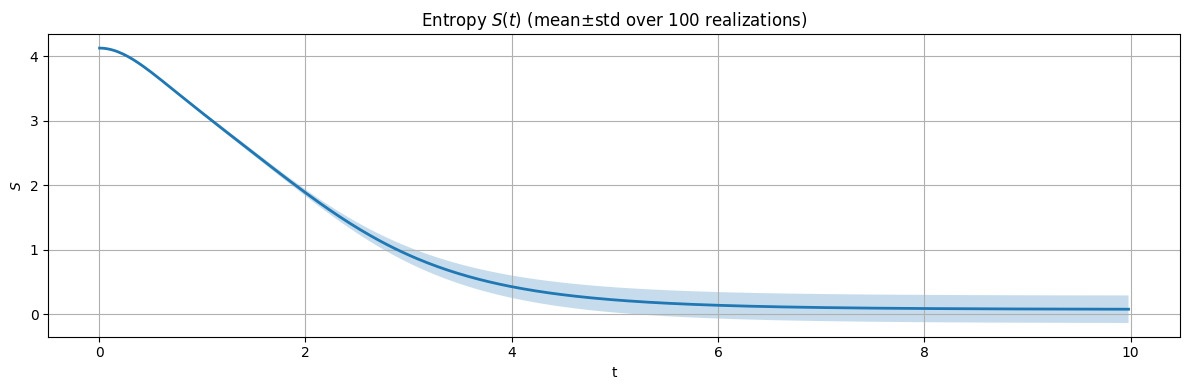

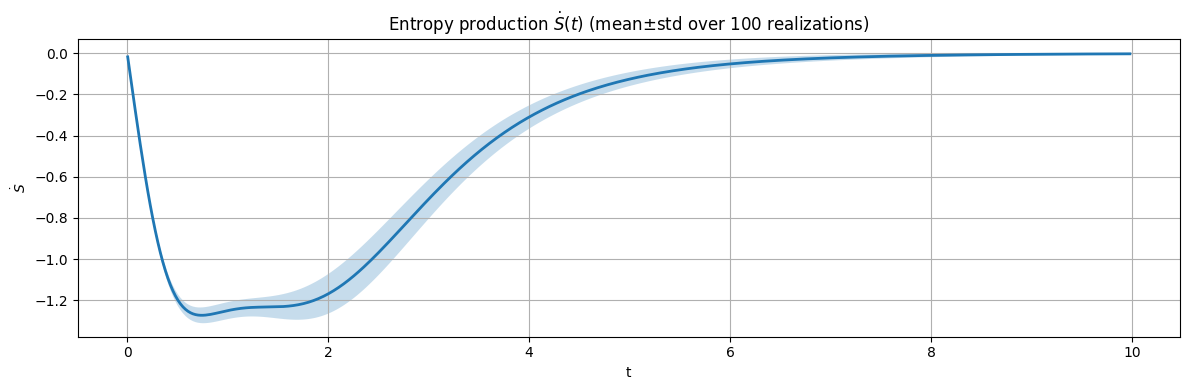

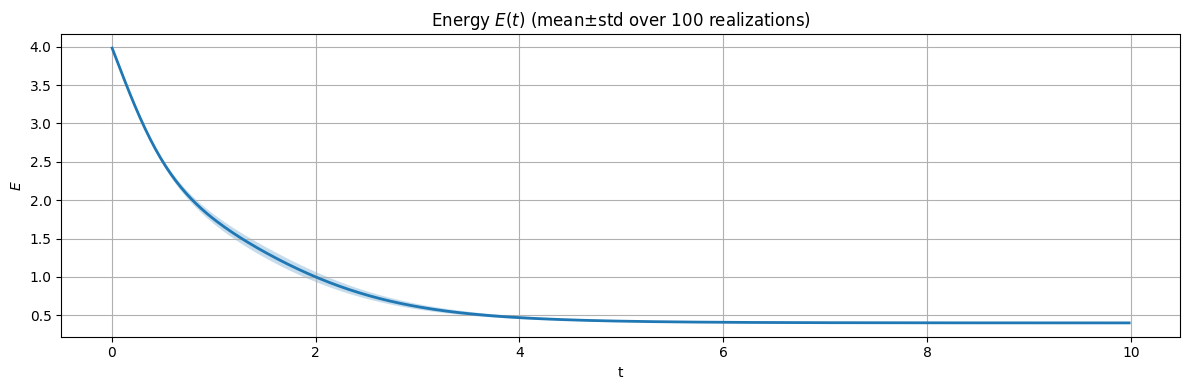

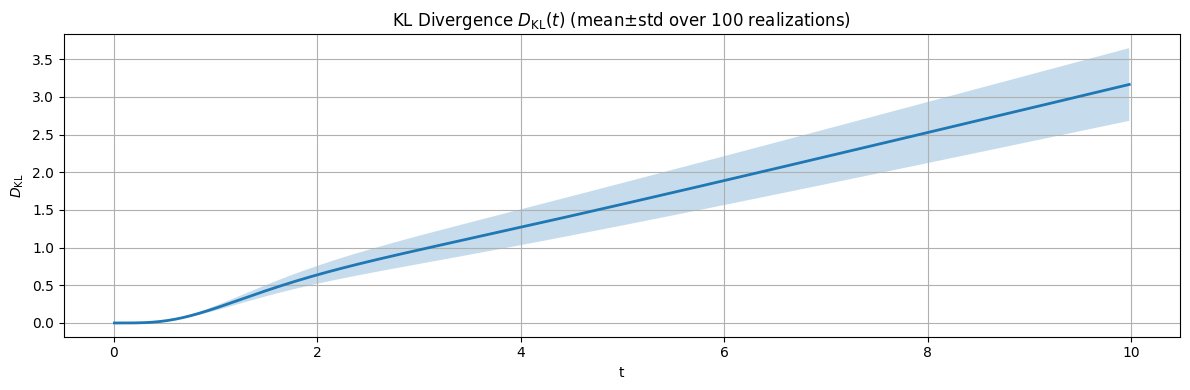

In [13]:
import numpy as np
import matplotlib.pyplot as plt

common_kwargs = dict(lw=2)
shade_alpha = 0.25   # trasparenza banda std

# ============================================================
# Load ONLY valid runs (good realizations)
# ============================================================
good_final_file = "thermo_noisy_cm_good_final.npz"   # <- quello che hai salvato
data = np.load(good_final_file, allow_pickle=True)

taus_samp     = data["taus_samp"]
good_idx      = data["good_idx"]
seeds_good    = data["seeds"]

entropy       = data["entropy"]        # shape (z_good, n_samp)
entropy_rate  = data["entropy_rate"]   # shape (z_good, n_samp)
energy        = data["energy"]         # shape (z_good, n_samp)
divergence    = data["divergence"]     # shape (z_good, n_samp)

print(f"Loaded {len(good_idx)} valid runs.")
print(f"taus_samp length: {len(taus_samp)}")

# ============================================================
# Utility: plot mean ± std ACROSS REALIZATIONS (axis=0)
# ============================================================
def plot_mean_std(x, y, title, ylabel):
    """
    y shape: (n_realizations, len(x))
    mean/std computed across realizations, NOT across time.
    """
    # safety: ignore NaNs just in case
    y_mean = np.nanmean(y, axis=0)
    y_std  = np.nanstd(y, axis=0)

    plt.figure(figsize=(12, 4))
    plt.plot(x, y_mean, **common_kwargs)
    plt.fill_between(
        x,
        y_mean - y_std,
        y_mean + y_std,
        alpha=shade_alpha
    )
    plt.title(title)
    plt.xlabel("t")
    plt.ylabel(ylabel)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ============================================================
# Entropy
# ============================================================
plot_mean_std(
    taus_samp,
    entropy,
    title=f"Entropy $S(t)$ (mean±std over {len(good_idx)} realizations)",
    ylabel="$S$"
)

# ============================================================
# Entropy production
# ============================================================
plot_mean_std(
    taus_samp,
    entropy_rate,
    title=f"Entropy production $\\dot{{S}}(t)$ (mean±std over {len(good_idx)} realizations)",
    ylabel=r"$\dot S$"
)

# ============================================================
# Energy
# ============================================================
plot_mean_std(
    taus_samp,
    energy,
    title=f"Energy $E(t)$ (mean±std over {len(good_idx)} realizations)",
    ylabel="$E$"
)

# ============================================================
# KL Divergence
# ============================================================
plot_mean_std(
    taus_samp,
    divergence,
    title=f"KL Divergence $D_{{\\mathrm{{KL}}}}(t)$ (mean±std over {len(good_idx)} realizations)",
    ylabel=r"$D_{\mathrm{KL}}$"
)



### DATA ###

In [14]:
dt = taus[1] - taus[0]
print(f"Δt = {dt}")
print(f"Number of steps: {len(taus)}")



# Density matrix computation
U = np.eye(N)
rho = U / np.trace(U)


entropy = []
entropy_rate = []
energy = []
divergence = []

eps = 1e-12

data_trj_d = np.load("dtraj_noisy_d.npz")
x_d = data_trj_d["x"]


for k in tqdm(range(len(taus))):

    # current state
    xk = x_d[:, k]
    t = taus[k]
    # Jacobian at time tk
    J = jac_noisy(t, xk, A_d, B, R)

    U, S, Sdot, E, div = thermo(t, U, J, dt, eps)

    entropy.append(S)
    entropy_rate.append(Sdot)
    energy.append(E)
    divergence.append(div)

entropy = np.array(entropy)
entropy_rate = np.array(entropy_rate)
energy = np.array(energy)
divergence = np.array(divergence)


Δt = 0.004999999999999998
Number of steps: 2000


100%|██████████| 2000/2000 [00:01<00:00, 1288.89it/s]


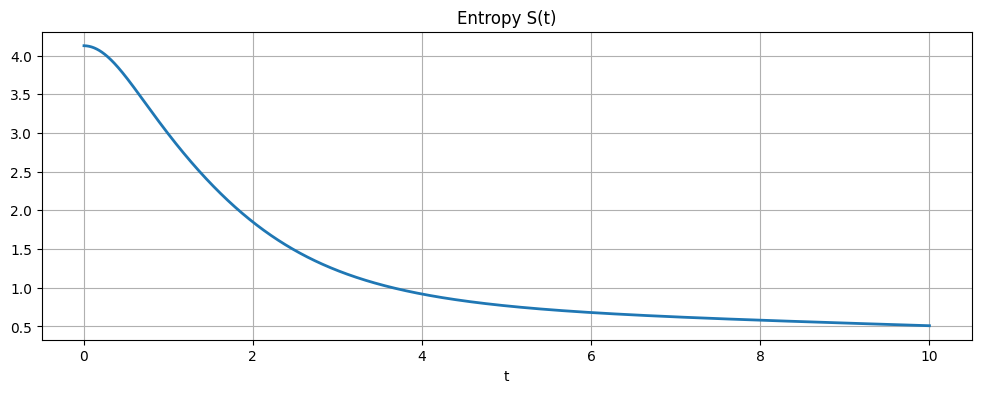

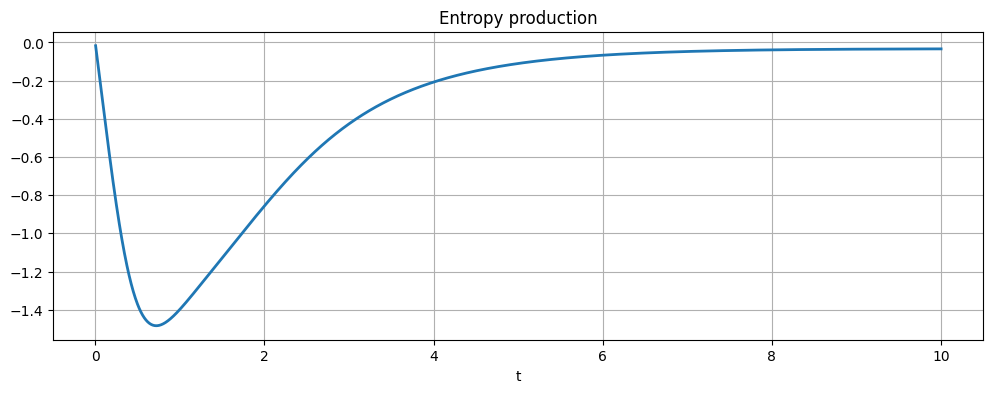

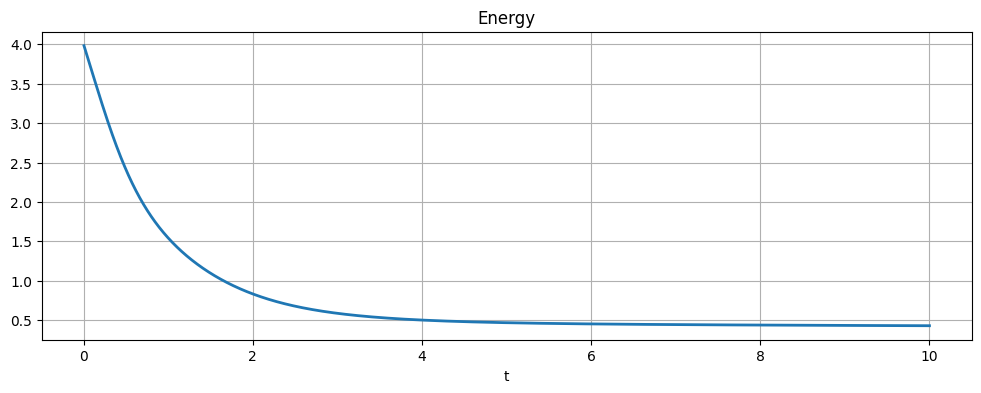

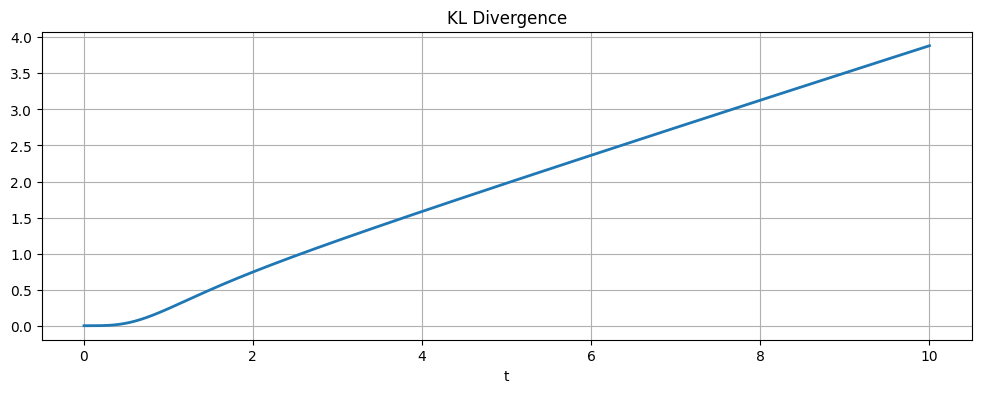

In [15]:
# results
plt.figure(figsize=(12,4))
plt.plot(taus, entropy, lw=2)
plt.title("Entropy S(t)")
plt.xlabel("t")
plt.grid(True)
plt.show()

plt.figure(figsize=(12,4))
plt.plot(taus, entropy_rate, lw=2)
plt.title("Entropy production")
plt.xlabel("t")
plt.grid(True)
plt.show()

plt.figure(figsize=(12,4))
plt.plot(taus, energy, lw=2)
plt.title("Energy")
plt.xlabel("t")
plt.grid(True)
plt.show()

plt.figure(figsize=(12,4))
plt.plot(taus, divergence, lw=2)
plt.title("KL Divergence")
plt.xlabel("t")
plt.grid(True)
plt.show()

In [16]:
#Saving
filename = f"dthermo_noisy_d.npz"
np.savez(filename, t=taus, S=entropy, Sdot=entropy_rate, E=energy, div=divergence)
